<a href="https://colab.research.google.com/github/Ayushmaantiwari/Kalman_Filter/blob/main/Kalman_Filter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install ipywidgets scipy matplotlib
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import cont2discrete
from scipy.optimize import minimize
import ipywidgets as widgets
from IPython.display import display, clear_output
import warnings
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

def motor_matrices(R=2.0, L=0.5, J=0.02, b=0.2, Kt=0.1, Ke=0.1, dt=0.02):
    A = np.array([[-b/J, Kt/J], [-Ke/L, -R/L]], dtype=float)
    B = np.array([[0.0], [1.0/L]])
    C = np.eye(2)
    D = np.zeros((2, 1))
    Ad, Bd, _, _, _ = cont2discrete((A, B, C, D), dt)
    return A, B, C, Ad, Bd

def kalman_update(x_pred, P_pred, measurement, C, Rm):
    innovation = measurement - C @ x_pred
    S = C @ P_pred @ C.T + Rm
    K = P_pred @ C.T @ np.linalg.pinv(S)
    x_est = x_pred + K @ innovation
    P_est = (np.eye(len(x_pred)) - K @ C) @ P_pred
    P_est = 0.5 * (P_est + P_est.T)
    return x_est, P_est

def mpc_control(x0, Ad, Bd, reference, horizon=15, Qw=20.0, Qi=0.2,
                Ru=0.15, u_min=-24.0, u_max=24.0, previous_u=0.0):
    # Optimize a sequence of future voltages; apply only its first element.
    n = Ad.shape[0]
    N = int(horizon)
    Q = np.diag([Qw, Qi])
    Rcost = float(Ru)

    def objective(U):
        x = x0.copy()
        cost = 0.0
        for k in range(N):
            u = U[k]
            x = Ad @ x + Bd[:, 0] * u
            e = x - np.array([reference, 0.0])
            cost += e @ Q @ e + Rcost * (u*u)
        cost += 0.5 * (U[0] - previous_u)**2
        return float(cost)

    U0 = np.full(N, np.clip(previous_u, u_min, u_max))
    result = minimize(objective, U0, method="L-BFGS-B",
                      bounds=[(u_min, u_max)]*N,
                      options={"maxiter": 45, "ftol": 1e-5})
    return float(result.x[0])

def simulate(params=None, seed=1, controller="kalman"):
    p = params or {}
    Rmtr = p.get("motor_R", 2.0)
    L = p.get("motor_L", 0.5)
    J = p.get("motor_J", 0.02)
    friction = p.get("motor_b", 0.2)
    Kt = p.get("Kt", 0.1)
    Ke = p.get("Ke", 0.1)
    dt = p.get("dt", 0.02)
    duration = p.get("duration", 5.0)
    ref_rpm = p.get("reference_rpm", 100.0)
    voltage_limit = p.get("voltage_limit", 24.0)
    horizon = p.get("horizon", 15)
    Qw = p.get("Qw", 20.0)
    Qi = p.get("Qi", 0.2)
    Ru = p.get("Ru", 0.15)
    meas_std_speed = p.get("measurement_noise_speed", 2.0)  # rad/s
    meas_std_current = p.get("measurement_noise_current", 0.15) # A
    process_std_speed = p.get("process_noise_speed", 0.15) # rad/s per step
    process_std_current = p.get("process_noise_current", 0.02) # A per step

    _, _, C, Ad, Bd = motor_matrices(Rmtr, L, J, friction, Kt, Ke, dt)
    rng = np.random.default_rng(seed)
    steps = int(duration / dt)
    ref = ref_rpm * 2*np.pi/60.0
    Rmeas = np.diag([meas_std_speed**2, meas_std_current**2])
    Qproc = np.diag([process_std_speed**2, process_std_current**2])

    x = np.zeros(2)       # true [speed rad/s, armature current A]
    xhat = np.zeros(2)    # Kalman estimate
    P = np.diag([1.0, 0.2])
    u_prev = 0.0

    t = np.arange(steps)*dt
    true_states = np.zeros((steps, 2))
    measured = np.zeros((steps, 2))
    estimated = np.zeros((steps, 2))
    voltages = np.zeros(steps)
    refs = np.full(steps, ref)

    for k in range(steps):
        # Noisy sensor measurements of both states
        y = C @ x + rng.multivariate_normal(np.zeros(2), Rmeas)
        measured[k] = y

        if controller == "kalman":
            # Correct prediction using the current measurement
            xhat, P = kalman_update(xhat, P, y, C, Rmeas)
            control_state = xhat.copy()
        else:
            # Baseline: controller uses noisy measured states directly
            control_state = y.copy()

        u = mpc_control(control_state, Ad, Bd, ref, horizon, Qw, Qi,
                        Ru, -voltage_limit, voltage_limit, u_prev)
        # Motor plant: nominal discrete dynamics + process disturbance
        x = Ad @ x + Bd[:, 0]*u + rng.multivariate_normal(np.zeros(2), Qproc)

        # Time update for Kalman filter (for next sample)
        if controller == "kalman":
            xhat = Ad @ xhat + Bd[:, 0]*u
            P = Ad @ P @ Ad.T + Qproc
        else:
            # Keep a model prediction only for consistent logging
            xhat = Ad @ xhat + Bd[:, 0]*u

        true_states[k] = x
        estimated[k] = xhat
        voltages[k] = u
        u_prev = u

    return {"t":t, "true":true_states, "measured":measured,
            "estimated":estimated, "voltage":voltages, "reference":refs,
            "dt":dt, "params":p}

def plot_result(result, title="Kalman Filter + MPC"):
    t = result["t"]
    true = result["true"]
    est = result["estimated"]
    meas = result["measured"]
    ref = result["reference"]
    u = result["voltage"]
    fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    ax[0].plot(t, true[:,0]*60/(2*np.pi), label="Actual speed")
    ax[0].plot(t, est[:,0]*60/(2*np.pi), "--", label="Estimated speed")
    ax[0].plot(t, meas[:,0]*60/(2*np.pi), alpha=.35, label="Noisy measured speed")
    ax[0].plot(t, ref*60/(2*np.pi), ":", linewidth=2, label="Reference speed")
    ax[0].set_ylabel("Speed (RPM)")
    ax[0].set_title(title)
    ax[0].legend(ncol=2)
    ax[1].plot(t, true[:,1], label="Actual armature current")
    ax[1].plot(t, est[:,1], "--", label="Estimated current")
    ax[1].plot(t, meas[:,1], alpha=.35, label="Noisy measured current")
    ax[1].set_ylabel("Current (A)")
    ax[1].legend(ncol=2)
    ax[2].step(t, u, where="post", label="Applied armature voltage")
    ax[2].set_ylabel("Voltage (V)")
    ax[2].set_xlabel("Time (s)")
    ax[2].legend()
    plt.tight_layout()
    plt.show()

def metrics(result):
    true = result["true"]
    est = result["estimated"]
    ref = result["reference"]
    speed_rmse = np.sqrt(np.mean((true[:,0]-est[:,0])**2))*60/(2*np.pi)
    current_rmse = np.sqrt(np.mean((true[:,1]-est[:,1])**2))
    speed_tracking_rmse = np.sqrt(np.mean((true[:,0]-ref)**2))*60/(2*np.pi)
    return speed_rmse, current_rmse, speed_tracking_rmse

print("Model and simulation functions are ready.")


Model and simulation functions are ready.


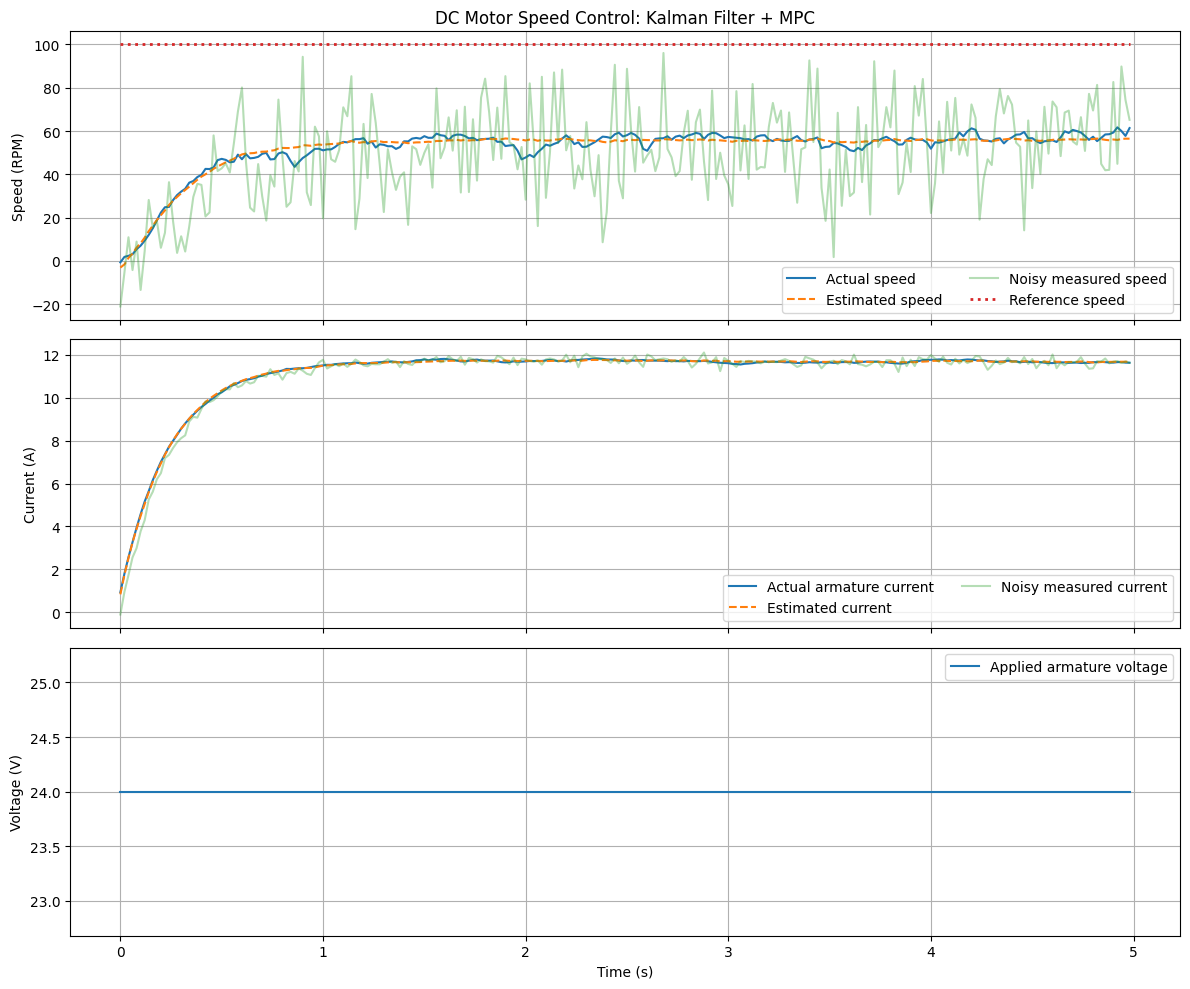

State estimation RMSE (speed): 2.490 RPM
State estimation RMSE (current): 0.0459 A
Speed tracking RMSE: 49.404 RPM


In [2]:
default_params = {
    "motor_R": 2.0, "motor_L": 0.5, "motor_J": 0.02, "motor_b": 0.2,
    "Kt": 0.1, "Ke": 0.1, "dt": 0.02, "duration": 5.0,
    "reference_rpm": 100.0, "voltage_limit": 24.0, "horizon": 15,
    "Qw": 20.0, "Qi": 0.2, "Ru": 0.15,
    "measurement_noise_speed": 2.0, "measurement_noise_current": 0.15,
    "process_noise_speed": 0.15, "process_noise_current": 0.02
}

kalman_run = simulate(default_params, seed=10, controller="kalman")
plot_result(kalman_run, "DC Motor Speed Control: Kalman Filter + MPC")
print("State estimation RMSE (speed): %.3f RPM" % metrics(kalman_run)[0])
print("State estimation RMSE (current): %.4f A" % metrics(kalman_run)[1])
print("Speed tracking RMSE: %.3f RPM" % metrics(kalman_run)[2])


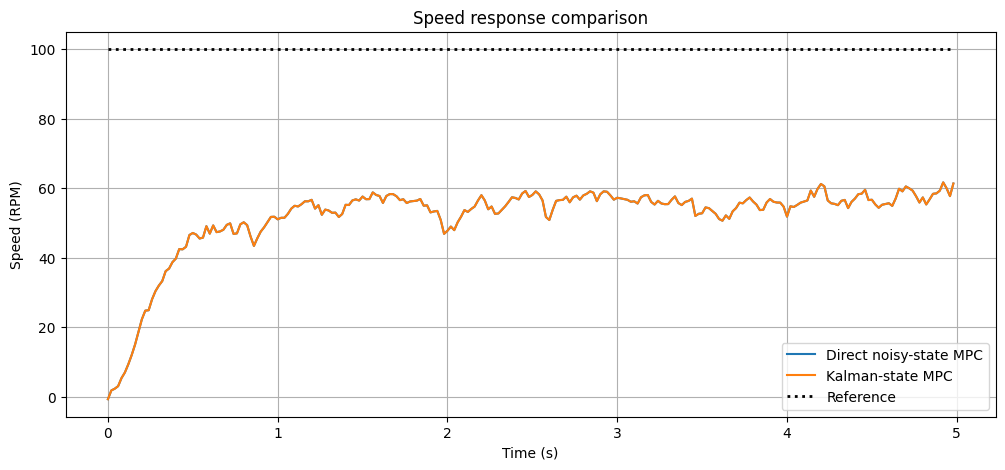

Controller                      Speed est. RMSE (RPM)   Current est. RMSE (A)   Tracking RMSE (RPM)
Direct noisy-state MPC                          2.614                  0.0563                49.404
Kalman-state MPC                                2.490                  0.0459                49.404


In [3]:
direct_run = simulate(default_params, seed=10, controller="direct")
filtered_run = simulate(default_params, seed=10, controller="kalman")

plt.figure(figsize=(12,5))
plt.plot(direct_run["t"], direct_run["true"][:,0]*60/(2*np.pi),
         label="Direct noisy-state MPC")
plt.plot(filtered_run["t"], filtered_run["true"][:,0]*60/(2*np.pi),
         label="Kalman-state MPC")
plt.plot(filtered_run["t"], filtered_run["reference"]*60/(2*np.pi),
         "k:", linewidth=2, label="Reference")
plt.xlabel("Time (s)"); plt.ylabel("Speed (RPM)")
plt.title("Speed response comparison"); plt.legend(); plt.show()

labels = ["Direct noisy-state MPC", "Kalman-state MPC"]
vals = [metrics(direct_run), metrics(filtered_run)]
print(f"{'Controller':30s} {'Speed est. RMSE (RPM)':>22s} {'Current est. RMSE (A)':>23s} {'Tracking RMSE (RPM)':>21s}")
for name, m in zip(labels, vals):
    print(f"{name:30s} {m[0]:22.3f} {m[1]:23.4f} {m[2]:21.3f}")


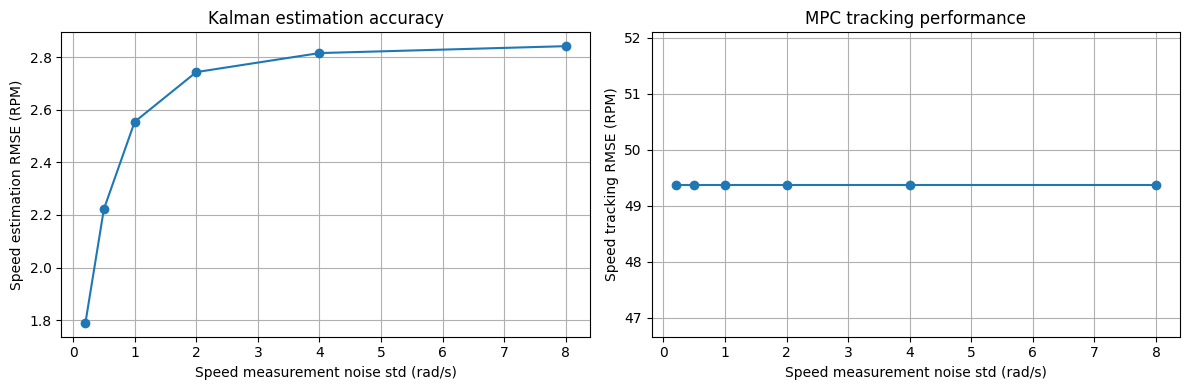

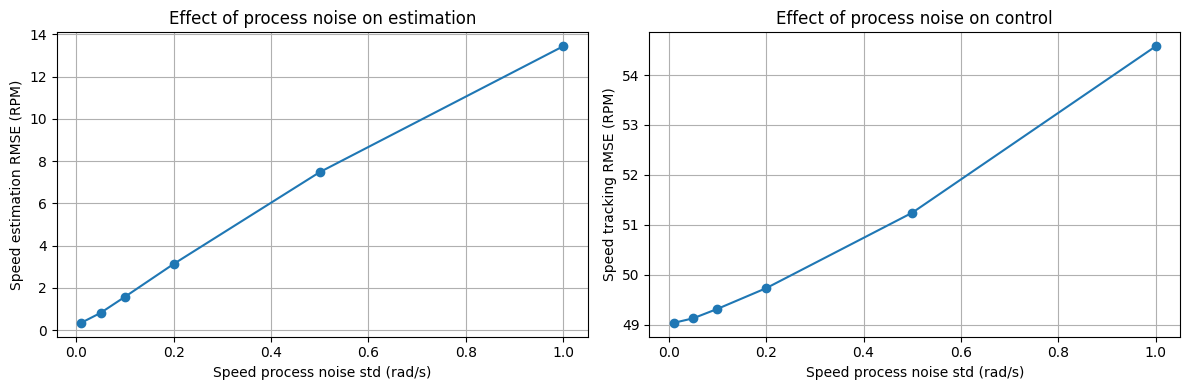

In [4]:
noise_levels = [0.2, 0.5, 1.0, 2.0, 4.0, 8.0]  # rad/s standard deviation
est_errors, track_errors = [], []
for noise in noise_levels:
    p = default_params.copy()
    p["measurement_noise_speed"] = noise
    r = simulate(p, seed=22, controller="kalman")
    m = metrics(r)
    est_errors.append(m[0])
    track_errors.append(m[2])

fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].plot(noise_levels, est_errors, "o-")
ax[0].set_xlabel("Speed measurement noise std (rad/s)")
ax[0].set_ylabel("Speed estimation RMSE (RPM)")
ax[0].set_title("Kalman estimation accuracy")
ax[1].plot(noise_levels, track_errors, "o-")
ax[1].set_xlabel("Speed measurement noise std (rad/s)")
ax[1].set_ylabel("Speed tracking RMSE (RPM)")
ax[1].set_title("MPC tracking performance")
plt.tight_layout(); plt.show()

process_levels = [0.01, 0.05, 0.1, 0.2, 0.5, 1.0]
process_errors, process_tracking = [], []
for noise in process_levels:
    p = default_params.copy()
    p["process_noise_speed"] = noise
    r = simulate(p, seed=23, controller="kalman")
    m = metrics(r)
    process_errors.append(m[0])
    process_tracking.append(m[2])

fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].plot(process_levels, process_errors, "o-")
ax[0].set_xlabel("Speed process noise std (rad/s)")
ax[0].set_ylabel("Speed estimation RMSE (RPM)")
ax[0].set_title("Effect of process noise on estimation")
ax[1].plot(process_levels, process_tracking, "o-")
ax[1].set_xlabel("Speed process noise std (rad/s)")
ax[1].set_ylabel("Speed tracking RMSE (RPM)")
ax[1].set_title("Effect of process noise on control")
plt.tight_layout(); plt.show()


In [5]:
style = {"description_width": "initial"}
layout = widgets.Layout(width="95%")
def slider(description, value, minv, maxv, step, readout_format=".2f"):
    return widgets.FloatSlider(description=description, value=value, min=minv,
                               max=maxv, step=step, readout_format=readout_format,
                               style=style, layout=layout, continuous_update=False)

R_w = slider("Armature resistance R (ohm)", 2.0, 0.2, 10, 0.1)
L_w = slider("Armature inductance L (H)", 0.5, 0.01, 2, 0.01)
J_w = slider("Rotor inertia J (kg m²)", 0.02, 0.001, 0.2, 0.001)
b_w = slider("Viscous friction b (N m s)", 0.2, 0.001, 2, 0.01)
Kt_w = slider("Torque constant Kt", 0.1, 0.01, 1, 0.01)
Ke_w = slider("Back-EMF constant Ke", 0.1, 0.01, 1, 0.01)
ref_w = widgets.IntSlider(description="Target speed (RPM)", value=100, min=0, max=300, step=5, style=style, layout=layout)
voltage_w = widgets.FloatSlider(description="Voltage limit (V)", value=24, min=5, max=48, step=1, style=style, layout=layout)
horizon_w = widgets.IntSlider(description="MPC prediction horizon", value=15, min=3, max=40, step=1, style=style, layout=layout)
Qw_w = slider("MPC speed weight Qω", 20, 1, 100, 1)
Qi_w = slider("MPC current weight Qi", 0.2, 0, 5, 0.05)
Ru_w = slider("MPC voltage weight R", 0.15, 0.01, 5, 0.01)
ms_w = slider("Speed measurement noise std (rad/s)", 2, 0, 10, 0.1)
mi_w = slider("Current measurement noise std (A)", 0.15, 0, 1, 0.01)
ps_w = slider("Speed process noise std (rad/s)", 0.15, 0, 2, 0.01)
pi_w = slider("Current process noise std (A)", 0.02, 0, 0.5, 0.005)

run_button = widgets.Button(description="Run simulation", button_style="success", icon="play")
output = widgets.Output()

def run_gui(_):
    with output:
        clear_output(wait=True)
        p = {
            "motor_R": R_w.value, "motor_L": L_w.value, "motor_J": J_w.value,
            "motor_b": b_w.value, "Kt": Kt_w.value, "Ke": Ke_w.value,
            "reference_rpm": ref_w.value, "voltage_limit": voltage_w.value,
            "horizon": horizon_w.value, "Qw": Qw_w.value, "Qi": Qi_w.value,
            "Ru": Ru_w.value, "measurement_noise_speed": ms_w.value,
            "measurement_noise_current": mi_w.value,
            "process_noise_speed": ps_w.value, "process_noise_current": pi_w.value,
            "duration": 5.0, "dt": 0.02
        }
        r_kf = simulate(p, seed=42, controller="kalman")
        r_direct = simulate(p, seed=42, controller="direct")
        plot_result(r_kf, "Interactive run: Kalman Filter + MPC")

        plt.figure(figsize=(12,4))
        plt.plot(r_direct["t"], r_direct["true"][:,0]*60/(2*np.pi), label="Direct noisy-state MPC")
        plt.plot(r_kf["t"], r_kf["true"][:,0]*60/(2*np.pi), label="Kalman-state MPC")
        plt.plot(r_kf["t"], r_kf["reference"]*60/(2*np.pi), "k:", label="Reference")
        plt.xlabel("Time (s)"); plt.ylabel("Speed (RPM)")
        plt.title("Controller comparison"); plt.legend(); plt.show()

        m1, m2 = metrics(r_direct), metrics(r_kf)
        print("Performance metrics (lower RMSE is better)")
        print(f"{'Metric':32s} {'Direct MPC':>14s} {'KF + MPC':>14s}")
        print(f"{'State speed estimation RMSE (RPM)':32s} {m1[0]:14.3f} {m2[0]:14.3f}")
        print(f"{'State current estimation RMSE (A)':32s} {m1[1]:14.4f} {m2[1]:14.4f}")
        print(f"{'Speed tracking RMSE (RPM)':32s} {m1[2]:14.3f} {m2[2]:14.3f}")

run_button.on_click(run_gui)
controls = widgets.VBox([
    widgets.HTML("<h3>Motor parameters</h3>"),
    R_w, L_w, J_w, b_w, Kt_w, Ke_w,
    widgets.HTML("<h3>Reference and MPC settings</h3>"),
    ref_w, voltage_w, horizon_w, Qw_w, Qi_w, Ru_w,
    widgets.HTML("<h3>Noise settings</h3>"),
    ms_w, mi_w, ps_w, pi_w,
    run_button
])
display(controls, output)


Output()